[*********************100%***********************]  2 of 2 completed


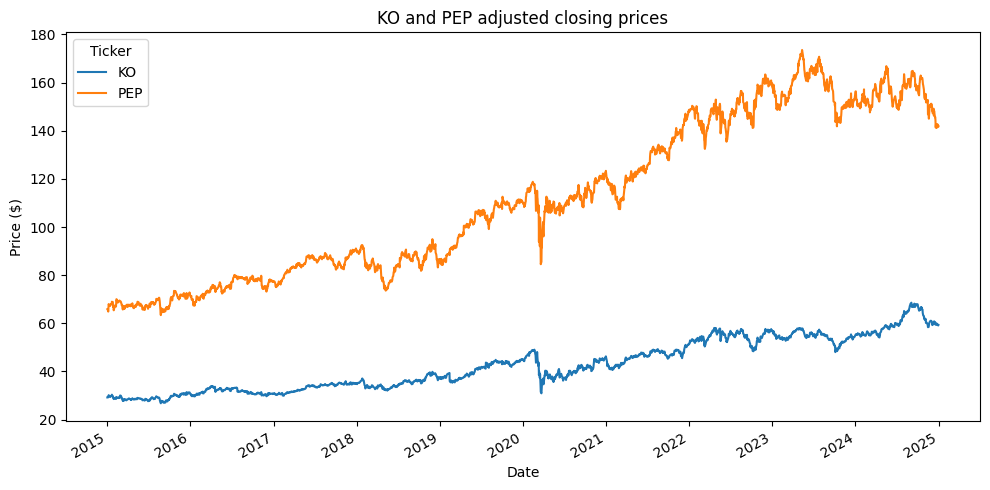

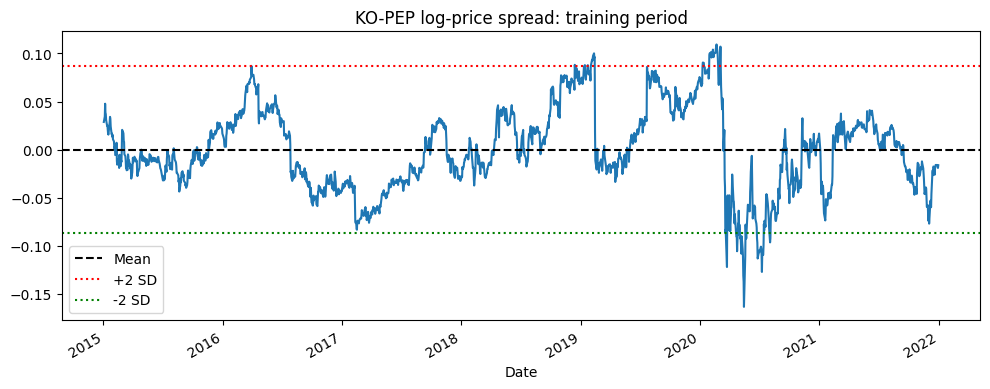

<Figure size 640x480 with 0 Axes>

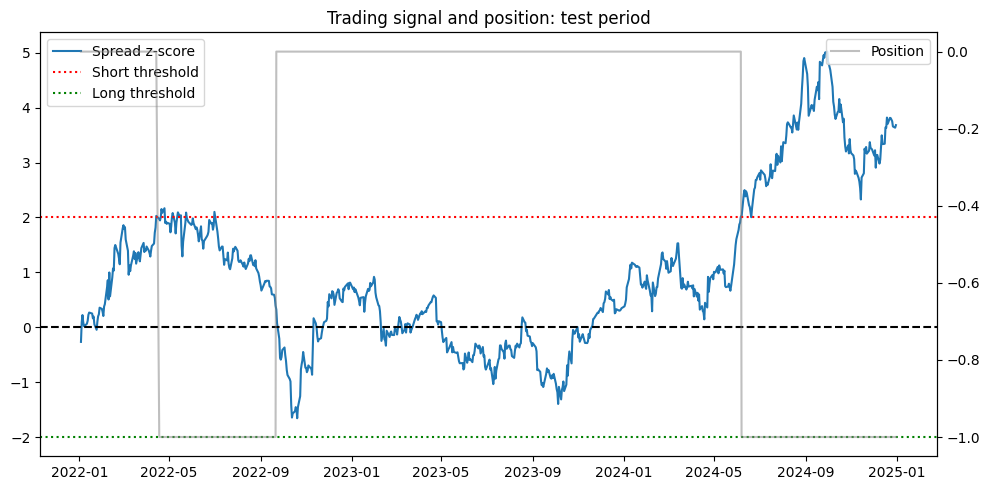

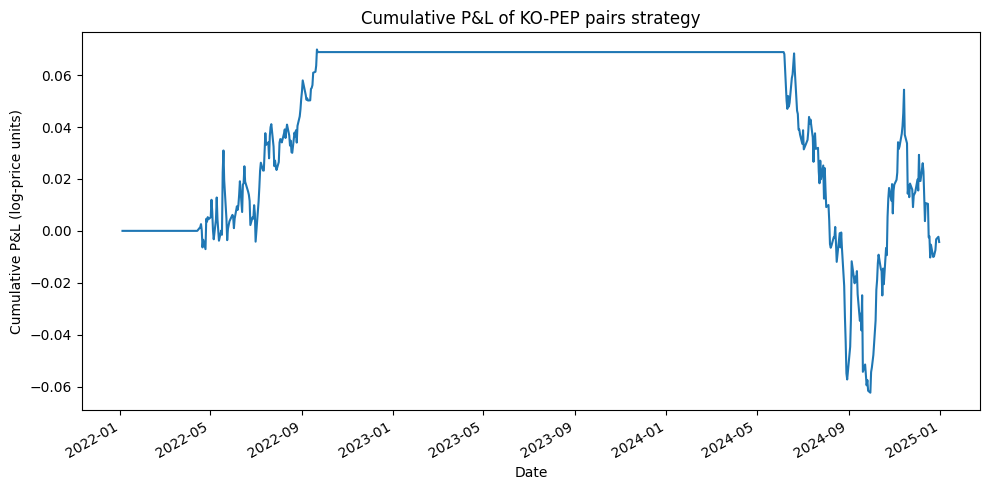

<Figure size 640x480 with 0 Axes>

In [12]:
# yfinance being Yahoo finance data
!pip install yfinance
import matplotlib.pyplot as plt

# importing and simplifying libraries
import yfinance as yf, pandas as pd, numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint

# fetching Coca-Cola (KO) and Pepsi (PEP)'s daily closing prices and adjusting prices
prices = yf.download(["KO", "PEP"], start="2015-01-01", end="2025-01-01",
                     auto_adjust=True)["Close"].dropna()
# converting prices to log prices
logp = np.log(prices)
# splitting data from training and test data
train, test = logp.loc[:"2021-12-31"], logp.loc["2022-01-01":]

# cointegration test between two companies data
t_stat, p_value, _ = coint(train["KO"], train["PEP"])

# printing results of cointegration test
# p-value below 0.05, so training data provides evidence to suggest log prices cointegrated
print(f"Cointegration statistic: {t_stat:.4f}")
print(f"Cointegration p-value: {p-value:.4f}")

# estimating long-run relationship by regressing prices
model = sm.OLS(train["KO"], sm.add_constant(train["PEP"])).fit()
alpha, beta = model.params
# calculating residual for both companies
spread = lambda df: df["KO"] - alpha - beta * df["PEP"]
# calculating training data's mean and standard deviation
mu, sigma = spread(train).mean(), spread(train).std()
# converting test spread into a z-score
z = (spread(test) - mu )/ sigma

# generating trading positions
pos, current = pd.Series(0.0, index = z.index), 0
for t in range(len(z)):
  if current == 0:
    # short spread when z>2 and long when z<-2
    current = -1 if z.iloc[t] > 2 else (1 if z.iloc[t] < -2 else 0)
  # close when reverting towards zero
  elif current == 1 and z.iloc[t] > -0.5: current = 0
  elif current == -1 and z.iloc[t] < 0.5: current = 0
  pos.iloc[t] = current
pos = pos.shift(1).fillna(0) # trade on the NEXT day (avoiding look-ahead bias)

spread_ret = spread(test).diff()
trades = pos.diff().abs().fillna(0)
cost = 0.0010
# estimating daily profit/ loss from the changes in spread
pnl = pos * spread_ret - trades * cost
equity = pnl.fillna(0).cumsum()

# plot of closing prices
prices.plot(title = "KO and PEP adjusted closing prices", figsize = (10, 5))
plt.ylabel("Price ($)")
plt.tight_layout()
plt.savefig("prices.png")
plt.show()

# plot of training spread
spread_train = spread(train)
spread_train.plot(title = "KO-PEP log-price spread: training period", figsize = (10, 4))
plt.axhline(mu, color = "black", linestyle = "--", label = "Mean")
plt.axhline(mu + 2 * sigma, color = "red", linestyle = ":", label = "+2 SD")
plt.axhline(mu - 2 * sigma, color = "green", linestyle = ":", label = "-2 SD")
plt.legend()
plt.tight_layout()
plt.savefig("training_spread.png")
plt.show()

# test-period z-score and positions
fig, ax1 = plt.subplots(figsize = (10, 5))
ax1.plot(z, label = "Spread z-score")
ax1.axhline(2, color = "red", linestyle = ":", label = "Short threshold")
ax1.axhline(-2, color = "green", linestyle = ":", label = "Long threshold")
ax1.axhline(0, color = "black", linestyle = "--")
ax2 = ax1.twinx()
ax2.plot(pos, color = "grey", alpha = 0.5, label = "Position")
ax1.set_title("Trading signal and position: test period")
ax1.legend(loc = "upper left")
ax2.legend(loc = "upper right")
plt.tight_layout()
plt.savefig("signals.png")
plt.show()

# plot of equity curve
equity.plot(title = "Cumulative Spread-Based P&L Proxy", figsize = (10, 5))
plt.ylabel("Cumulative spread units")
plt.tight_layout()
plt.savefig("equity_curve.png")
plt.show()
